# A1 — Vision Transformers em um problema de marketing: classificação de produtos de catálogo de e-commerce

**Disciplina:** Visão Computacional com CNNs e Transformers — Projeto da Disciplina
**Autor:** Raphael Alves Carneiro

| Item | Valor |
|---|---|
| Ambiente | Google Colab, GPU T4 (Runtime → Change runtime type → T4 GPU) |
| Memória de GPU | ~2 GB no ViT do zero; ~7 GB no fine-tuning do ViT-Base (batch 32, AMP) |
| RAM | ~4 GB |
| Tempo estimado | ~20 a 25 min no total (medido na T4): dados ~2 min, testes dos módulos <1 min, ViT do zero ~8 min, fine-tuning ~6 min, visualizações ~3 min |
| Dados | Hugging Face `ashraq/fashion-product-images-small` (versão reduzida do *Fashion Product Images Dataset*, Kaggle, P. Aggarwal) |

**Roteiro**
1. Problema e dataset
2. Módulos do zero: scaled dot-product attention e multi-head attention (com testes)
3. TransformerEncoderBlock, patch embedding, CLS token e positional encoding
4. ViT completo e demonstração de por que a positional encoding é necessária
5. Treino do ViT do zero
6. Fine-tuning de um ViT pré-treinado
7. Comparação quantitativa
8. Attention maps e interpretação
9. Análises escritas: BERT vs. ViT no pré-treinamento, DeiT e Swin, ViT vs. CNN, escolha final e o que eu mudaria

## 1. Problema e dataset

**Problema.** Em marketplaces e e-commerce, cada produto precisa estar na categoria certa para aparecer no filtro certo, entrar no feed de anúncios certo (Google Shopping, Meta Catalog, Mercado Livre Ads) e ser comparado com os concorrentes certos. Em catálogos grandes essa classificação ainda é feita à mão ou por texto do título, e erra bastante quando o vendedor escreve mal o anúncio. Um classificador a partir da foto resolve parte disso: sugere a categoria no cadastro e audita o catálogo existente.

**Dataset.** Uso o *Fashion Product Images*, com ~44 mil produtos de uma loja online indiana, fotografados em fundo branco. Recortei **10 tipos de artigo** (`articleType`) escolhidos de propósito para ter pares difíceis, porque um problema fácil demais não permitiria comparar arquiteturas:

- **Parte de cima:** `Tshirts`, `Shirts`, `Tops`. Camiseta, camisa e blusa feminina diferem em gola, botões e caimento.
- **Calçados:** `Casual Shoes`, `Sports Shoes`, `Heels`. Tênis casual e esportivo são muito parecidos.
- **Outros:** `Jeans`, `Handbags`, `Watches`, `Sunglasses`.

Limitei a **1.000 imagens por classe** (amostragem aleatória com semente fixa) para manter o tempo de treino compatível com a T4 e reduzir o desbalanceamento original, em que só `Tshirts` tem ~7 mil itens. `Jeans` tem menos de 1.000 no dataset, então fica como a classe minoritária.

### 1.1 Configuração do ambiente

In [1]:
!pip -q install -U datasets transformers

import os, math, json, time, random, copy
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, f1_score, classification_report

SEED = 42
def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
seed_everything()
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP = DEVICE.type == "cuda"
print("Device:", DEVICE, "|", torch.cuda.get_device_name(0) if AMP else "sem GPU")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 559.1/559.1 kB 37.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.3/12.3 MB 124.9 MB/s eta 0:00:00
Device: cuda | Tesla T4


In [2]:
SAVE_TO_DRIVE = True
OUT_DIR = Path("/content/outputs/A1")
if SAVE_TO_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        OUT_DIR = Path("/content/drive/MyDrive/PD_VisaoComputacional/A1")
    except Exception as e:
        print("Drive não montado, salvando localmente:", e)
OUT_DIR.mkdir(parents=True, exist_ok=True)
print("Saídas em:", OUT_DIR)

Drive não montado, salvando localmente: mount failed
Saídas em: /content/outputs/A1


### 1.2 Carregamento e recorte do dataset

In [3]:
from datasets import load_dataset

CLASSES = ["Tshirts", "Shirts", "Tops", "Jeans", "Casual Shoes",
           "Sports Shoes", "Heels", "Handbags", "Watches", "Sunglasses"]
CAP_PER_CLASS = 1000

hf_ds = load_dataset("ashraq/fashion-product-images-small", split="train")
meta = hf_ds.select_columns(["articleType"]).to_pandas()
missing = [c for c in CLASSES if c not in set(meta.articleType)]
assert not missing, f"Classes ausentes: {missing}. Disponíveis: {meta.articleType.value_counts().head(30)}"

rng = np.random.RandomState(SEED)
sel_idx, sel_y = [], []
for ci, c in enumerate(CLASSES):
    idx = meta.index[meta.articleType == c].to_numpy()
    idx = rng.choice(idx, size=min(CAP_PER_CLASS, len(idx)), replace=False)
    sel_idx += idx.tolist(); sel_y += [ci] * len(idx)

def to_square_rgb(img, fill=255):
    # As fotos são retrato (~60x80). Completo com branco até ficar quadrado, em vez de esticar:
    # esticar distorceria proporções que diferenciam, por exemplo, camisa de camiseta.
    img = img.convert("RGB")
    w, h = img.size; s = max(w, h)
    canvas = Image.new("RGB", (s, s), (fill, fill, fill))
    canvas.paste(img, ((s - w) // 2, (s - h) // 2))
    return canvas

t0 = time.time()
sub = hf_ds.select(sel_idx)
IMGS = [to_square_rgb(im) for im in sub["image"]]
YS = np.array(sel_y)
print(f"{len(IMGS)} imagens carregadas em {time.time()-t0:.0f}s | tamanho típico: {IMGS[0].size}")
print(pd.Series(YS).map(dict(enumerate(CLASSES))).value_counts())

README.md:   0%|          | 0.00/867 [00:00<?, ?B/s]

data/train-00000-of-00002-6cff4c59f91661(…): reconstructing file:   0%|          |  0.00B /  136MB            

data/train-00000-of-00002-6cff4c59f91661(…): downloading bytes:           |  0.00B            

data/train-00001-of-00002-bb459e5ac5f01e(…): reconstructing file:   0%|          |  0.00B /  135MB            

data/train-00001-of-00002-bb459e5ac5f01e(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/44072 [00:00<?, ? examples/s]

9602 imagens carregadas em 7s | tamanho típico: (80, 80)
Tshirts         1000
Shirts          1000
Tops            1000
Casual Shoes    1000
Sports Shoes    1000
Heels           1000
Watches         1000
Handbags        1000
Sunglasses      1000
Jeans            602
Name: count, dtype: int64


treino=6721 | validação=1440 | teste=1441


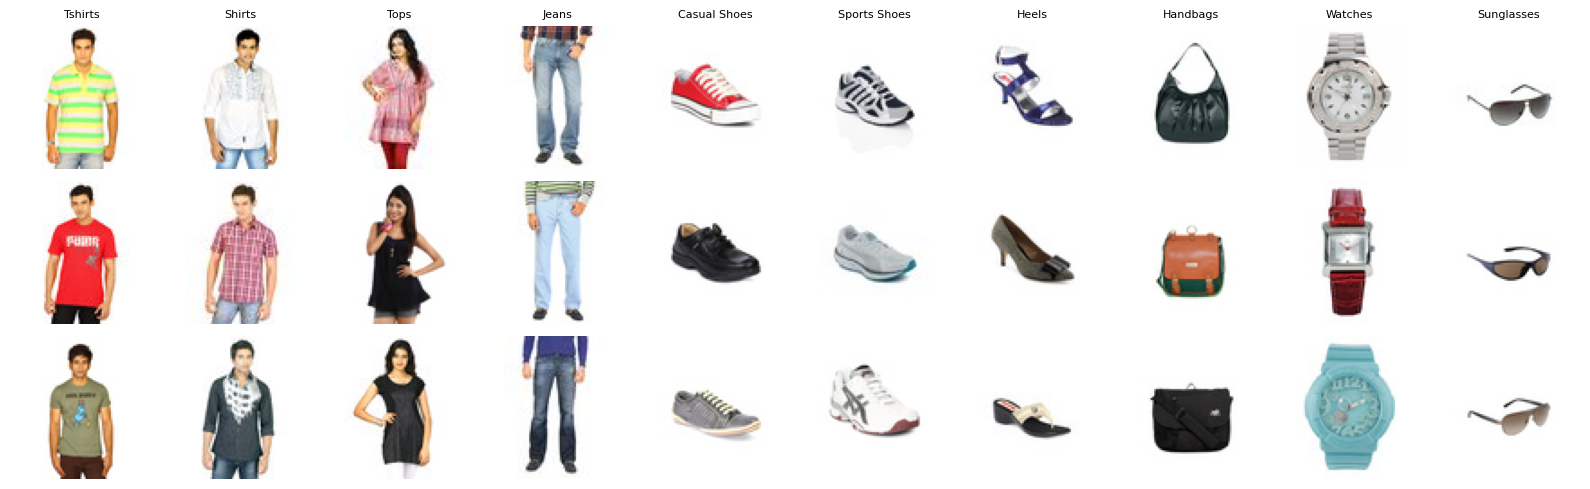

In [4]:
idx_all = np.arange(len(YS))
tr_idx, tmp_idx = train_test_split(idx_all, test_size=0.30, stratify=YS, random_state=SEED)
va_idx, te_idx = train_test_split(tmp_idx, test_size=0.50, stratify=YS[tmp_idx], random_state=SEED)
NUM_CLASSES = len(CLASSES)
print(f"treino={len(tr_idx)} | validação={len(va_idx)} | teste={len(te_idx)}")

fig, axes = plt.subplots(3, NUM_CLASSES, figsize=(NUM_CLASSES * 1.6, 5))
for j, c in enumerate(CLASSES):
    for i, k in enumerate(np.where(YS[tr_idx] == j)[0][:3]):
        axes[i, j].imshow(IMGS[tr_idx[k]]); axes[i, j].axis("off")
    axes[0, j].set_title(c, fontsize=8)
plt.tight_layout(); plt.savefig(OUT_DIR / "a1_amostras.png", dpi=130); plt.show()

## 2. Módulos de attention implementados do zero

A ideia central do attention é que cada token decide *quanto* olhar para cada um dos outros. Para isso cada token gera uma **query** (o que procura), uma **key** (o que oferece) e um **value** (o conteúdo que repassa):

$$\text{Attention}(Q,K,V) = \text{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}}\right)V$$

A divisão por $\sqrt{d_k}$ existe porque o produto escalar entre vetores de dimensão $d_k$ cresce com $d_k$. Sem ela, o softmax satura em quase one-hot e o gradiente praticamente zera.

Na multi-head attention implementei **uma classe `AttentionHead` por cabeça, cada uma com suas próprias projeções $W_q, W_k, W_v$**, e concateno as saídas antes da projeção final $W_o$. Bibliotecas fazem isso com uma única matriz grande por eficiência; o resultado é matematicamente o mesmo, e o teste 5 abaixo prova isso comparando com a `nn.MultiheadAttention` do PyTorch.

In [5]:
class ScaledDotProductAttention(nn.Module):
    # softmax(Q K^T / sqrt(d_k)) V. Retorna a saída e os pesos de atenção (antes do dropout).
    def __init__(self, dropout=0.0):
        super().__init__()
        self.dropout = nn.Dropout(dropout)

    def forward(self, q, k, v, mask=None):
        d_k = q.size(-1)
        scores = q @ k.transpose(-2, -1) / math.sqrt(d_k)          # (..., Nq, Nk)
        if mask is not None:                                      # mask: 1 = pode olhar, 0 = bloqueado
            scores = scores.masked_fill(mask == 0, float("-inf"))
        attn = scores.softmax(dim=-1)
        return self.dropout(attn) @ v, attn


class AttentionHead(nn.Module):
    # Uma cabeça: projeções Q, K, V próprias e independentes das demais cabeças.
    def __init__(self, d_model, d_head, dropout=0.0):
        super().__init__()
        self.W_q = nn.Linear(d_model, d_head)
        self.W_k = nn.Linear(d_model, d_head)
        self.W_v = nn.Linear(d_model, d_head)
        self.attention = ScaledDotProductAttention(dropout)

    def forward(self, x_q, x_kv, mask=None):
        return self.attention(self.W_q(x_q), self.W_k(x_kv), self.W_v(x_kv), mask)


class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, num_heads, dropout=0.0, proj_dropout=0.0):
        super().__init__()
        assert d_model % num_heads == 0, "d_model precisa ser divisível por num_heads"
        self.num_heads, self.d_head = num_heads, d_model // num_heads
        self.heads = nn.ModuleList([AttentionHead(d_model, self.d_head, dropout) for _ in range(num_heads)])
        self.W_o = nn.Linear(d_model, d_model)
        self.proj_drop = nn.Dropout(proj_dropout)

    def forward(self, x_q, x_kv=None, mask=None):
        x_kv = x_q if x_kv is None else x_kv                        # self-attention por padrão
        outs, attns = zip(*[h(x_q, x_kv, mask) for h in self.heads])
        concat = torch.cat(outs, dim=-1)                            # (B, N, H*d_head) = (B, N, d_model)
        return self.proj_drop(self.W_o(concat)), torch.stack(attns, dim=1)   # pesos: (B, H, Nq, Nk)

In [6]:
# Testes unitários dos módulos de attention
torch.manual_seed(0)
B, N, D, H = 2, 7, 32, 4

def test_sdpa_shapes_and_normalization():
    q, k, v = torch.randn(B, N, 8), torch.randn(B, N, 8), torch.randn(B, N, 16)
    out, attn = ScaledDotProductAttention()(q, k, v)
    assert out.shape == (B, N, 16) and attn.shape == (B, N, N)
    assert torch.allclose(attn.sum(-1), torch.ones(B, N), atol=1e-6), "linhas do softmax devem somar 1"

def test_sdpa_matches_pytorch():
    q, k, v = torch.randn(B, H, N, 8), torch.randn(B, H, N, 8), torch.randn(B, H, N, 8)
    out, _ = ScaledDotProductAttention()(q, k, v)
    assert torch.allclose(out, F.scaled_dot_product_attention(q, k, v), atol=1e-5)

def test_sdpa_mask():
    q = k = v = torch.randn(1, 4, 8)
    mask = torch.tensor([[1, 1, 0, 0]]).expand(4, 4)              # só as 2 primeiras posições visíveis
    _, attn = ScaledDotProductAttention()(q, k, v, mask)
    assert torch.all(attn[..., 2:] == 0) and torch.allclose(attn.sum(-1), torch.ones(1, 4))

def test_mha_shapes_and_independent_heads():
    mha = MultiHeadAttention(D, H)
    out, attn = mha(torch.randn(B, N, D))
    assert out.shape == (B, N, D) and attn.shape == (B, H, N, N)
    ids = {id(h.W_q.weight) for h in mha.heads}
    assert len(ids) == H, "cada cabeça precisa ter sua própria W_q"
    assert all(h.W_q.weight.shape == (D // H, D) for h in mha.heads)

def test_mha_matches_pytorch_multihead():
    # Copio os pesos das cabeças para a nn.MultiheadAttention (que usa uma matriz fundida)
    # e verifico que saída e pesos de atenção por cabeça são idênticos.
    mha = MultiHeadAttention(D, H).eval()
    ref = nn.MultiheadAttention(D, H, batch_first=True).eval()
    with torch.no_grad():
        Wq = torch.cat([h.W_q.weight for h in mha.heads]); bq = torch.cat([h.W_q.bias for h in mha.heads])
        Wk = torch.cat([h.W_k.weight for h in mha.heads]); bk = torch.cat([h.W_k.bias for h in mha.heads])
        Wv = torch.cat([h.W_v.weight for h in mha.heads]); bv = torch.cat([h.W_v.bias for h in mha.heads])
        ref.in_proj_weight.copy_(torch.cat([Wq, Wk, Wv])); ref.in_proj_bias.copy_(torch.cat([bq, bk, bv]))
        ref.out_proj.weight.copy_(mha.W_o.weight); ref.out_proj.bias.copy_(mha.W_o.bias)
    x = torch.randn(B, N, D)
    out, attn = mha(x)
    out_ref, attn_ref = ref(x, x, x, average_attn_weights=False)
    assert torch.allclose(out, out_ref, atol=1e-5) and torch.allclose(attn, attn_ref, atol=1e-6)

def test_mha_gradients_reach_every_head():
    mha = MultiHeadAttention(D, H)
    mha(torch.randn(B, N, D))[0].sum().backward()
    assert all(h.W_q.weight.grad is not None and h.W_q.weight.grad.abs().sum() > 0 for h in mha.heads)

for t in [test_sdpa_shapes_and_normalization, test_sdpa_matches_pytorch, test_sdpa_mask,
          test_mha_shapes_and_independent_heads, test_mha_matches_pytorch_multihead,
          test_mha_gradients_reach_every_head]:
    t(); print("✓", t.__name__)

✓ test_sdpa_shapes_and_normalization
✓ test_sdpa_matches_pytorch
✓ test_sdpa_mask
✓ test_mha_shapes_and_independent_heads
✓ test_mha_matches_pytorch_multihead
✓ test_mha_gradients_reach_every_head


## 3. TransformerEncoderBlock, patch embedding, CLS token e positional encoding

**Encoder block.** Segui a variante *pre-norm* usada no ViT: `x = x + MHA(LN(x))` e depois `x = x + FFN(LN(x))`. As conexões residuais deixam o gradiente passar direto pelas camadas, e o LayerNorm antes de cada subcamada estabiliza o treino sem precisar de warmup muito longo. O feedforward tem duas camadas lineares com GELU no meio: a primeira expande a dimensão e a segunda projeta de volta.

**Patch embedding.** A imagem é cortada em patches não sobrepostos de $P \times P$. Cada patch é achatado ($P \cdot P \cdot 3$ valores) e passa por uma camada linear que o leva para $d_{model}$. Implementei com `unfold` + `nn.Linear` para deixar a operação explícita (é equivalente a uma `Conv2d` com kernel = stride = $P$).

**CLS token.** Um vetor aprendível prefixado à sequência. Ele não corresponde a nenhum patch, então só consegue informação pela atenção. Ao final, a saída dele resume a imagem e alimenta o classificador.

**Positional encoding.** Uso embeddings de posição **aprendíveis**, um vetor por posição (65 = 64 patches + CLS), somados aos tokens, como no ViT original. A seção 4 mostra, com um experimento, por que sem isso o modelo não sabe onde cada patch está.

In [7]:
class FeedForward(nn.Module):
    def __init__(self, d_model, hidden_dim, dropout=0.0):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d_model, hidden_dim), nn.GELU(), nn.Dropout(dropout),
                                 nn.Linear(hidden_dim, d_model), nn.Dropout(dropout))
    def forward(self, x): return self.net(x)


class TransformerEncoderBlock(nn.Module):
    def __init__(self, d_model, num_heads, mlp_dim, dropout=0.1, attn_dropout=0.0):
        super().__init__()
        self.norm1 = nn.LayerNorm(d_model)
        self.attn = MultiHeadAttention(d_model, num_heads, attn_dropout, dropout)
        self.norm2 = nn.LayerNorm(d_model)
        self.ffn = FeedForward(d_model, mlp_dim, dropout)

    def forward(self, x, mask=None):
        a, w = self.attn(self.norm1(x), mask=mask)
        x = x + a                         # residual 1
        x = x + self.ffn(self.norm2(x))   # residual 2
        return x, w


class PatchEmbedding(nn.Module):
    def __init__(self, img_size, patch_size, in_ch, d_model):
        super().__init__()
        assert img_size % patch_size == 0
        self.patch_size = patch_size
        self.grid = img_size // patch_size
        self.num_patches = self.grid ** 2
        self.proj = nn.Linear(patch_size * patch_size * in_ch, d_model)

    def forward(self, x):                                   # x: (B, C, H, W)
        B, C, H, W = x.shape; p = self.patch_size
        x = x.unfold(2, p, p).unfold(3, p, p)                # (B, C, H/p, W/p, p, p)
        x = x.permute(0, 2, 3, 1, 4, 5).reshape(B, -1, C * p * p)   # ordem raster: linha a linha
        return self.proj(x)                                  # (B, N, d_model)


class VisionTransformer(nn.Module):
    def __init__(self, img_size=64, patch_size=8, in_ch=3, num_classes=10, d_model=192, depth=6,
                 num_heads=6, mlp_dim=384, dropout=0.1, attn_dropout=0.0, use_pos_embedding=True):
        super().__init__()
        self.patch_embed = PatchEmbedding(img_size, patch_size, in_ch, d_model)
        n = self.patch_embed.num_patches
        self.cls_token = nn.Parameter(torch.zeros(1, 1, d_model))
        self.pos_embed = nn.Parameter(torch.zeros(1, n + 1, d_model))
        self.use_pos_embedding = use_pos_embedding
        self.pos_drop = nn.Dropout(dropout)
        self.blocks = nn.ModuleList([TransformerEncoderBlock(d_model, num_heads, mlp_dim, dropout, attn_dropout)
                                     for _ in range(depth)])
        self.norm = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, num_classes)
        nn.init.trunc_normal_(self.pos_embed, std=0.02); nn.init.trunc_normal_(self.cls_token, std=0.02)
        self.apply(self._init_weights)

    @staticmethod
    def _init_weights(m):
        if isinstance(m, nn.Linear):
            nn.init.trunc_normal_(m.weight, std=0.02)
            if m.bias is not None: nn.init.zeros_(m.bias)
        elif isinstance(m, nn.LayerNorm):
            nn.init.ones_(m.weight); nn.init.zeros_(m.bias)

    def forward(self, x, return_attn=False):
        x = self.patch_embed(x)                                        # (B, N, D)
        x = torch.cat([self.cls_token.expand(x.size(0), -1, -1), x], dim=1)   # (B, N+1, D)
        if self.use_pos_embedding:
            x = x + self.pos_embed
        x = self.pos_drop(x)
        attns = []
        for blk in self.blocks:
            x, w = blk(x); attns.append(w)
        logits = self.head(self.norm(x)[:, 0])                         # classifica pela saída do CLS
        return (logits, attns) if return_attn else logits

In [8]:
# Testes do encoder block, do patch embedding e do ViT completo
def test_encoder_block():
    blk = TransformerEncoderBlock(D, H, 64)
    x = torch.randn(B, N, D); y, w = blk(x)
    assert y.shape == x.shape and w.shape == (B, H, N, N)
    assert len([m for m in blk.ffn.net if isinstance(m, nn.Linear)]) == 2

def test_patch_embedding_raster_order():
    pe = PatchEmbedding(16, 4, 3, 8)
    nn.init.zeros_(pe.proj.bias)
    img = torch.zeros(1, 3, 16, 16); img[:, :, 0:4, 4:8] = 1.0     # só o 2º patch (linha 0, coluna 1) aceso
    tok = pe(img)
    assert tok.shape == (1, 16, 8)
    nonzero = (tok.abs().sum(-1) > 0).nonzero()[:, 1].tolist()
    assert nonzero == [1], nonzero

def test_vit_forward():
    vit = VisionTransformer(img_size=64, patch_size=8, num_classes=10, d_model=48, depth=2, num_heads=4, mlp_dim=96)
    logits, attns = vit(torch.randn(2, 3, 64, 64), return_attn=True)
    assert logits.shape == (2, 10) and len(attns) == 2 and attns[0].shape == (2, 4, 65, 65)

for t in [test_encoder_block, test_patch_embedding_raster_order, test_vit_forward]:
    t(); print("✓", t.__name__)

✓ test_encoder_block
✓ test_patch_embedding_raster_order
✓ test_vit_forward


## 4. Por que attention sem positional encoding não preserva informação posicional

A self-attention trata a entrada como um **conjunto**, não como uma sequência. Se eu permuto os tokens com uma matriz de permutação $P$:

$$\text{softmax}\!\left(\frac{(PX W_q)(PX W_k)^\top}{\sqrt{d_k}}\right)(PX W_v) = P\,\text{softmax}\!\left(\frac{X W_q W_k^\top X^\top}{\sqrt{d_k}}\right) P^\top P X W_v = P\cdot\text{Attention}(X)$$

porque o softmax por linha comuta com a permutação e $P^\top P = I$. A saída é só a mesma saída, embaralhada da mesma forma (**equivariância a permutação**). O LayerNorm e o FFN atuam token a token e preservam essa propriedade. Como o CLS lê todos os tokens pela atenção, a representação final dele fica **idêntica** para qualquer ordem dos patches.

Na prática: sem positional encoding, uma foto de tênis e a mesma foto cortada em 64 pedaços embaralhados geram exatamente os mesmos logits. O modelo vira um "saco de patches" e não consegue usar relações como "sola embaixo, cano em cima". Somar um vetor diferente para cada posição quebra essa simetria. O teste abaixo verifica as duas situações.

positional encoding=False | diferença máxima nos logits entre original e embaralhada: 8.94e-08
positional encoding=True  | diferença máxima nos logits entre original e embaralhada: 6.71e-04


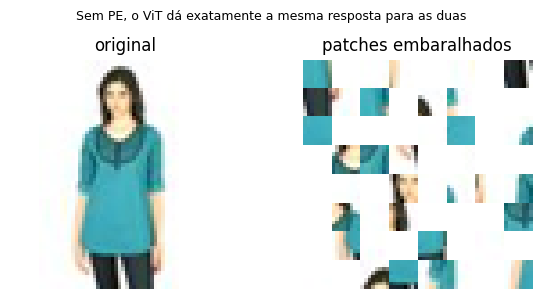

In [9]:
def shuffle_patches(img, patch, perm):
    # Reorganiza os patches de uma imagem (C,H,W) segundo a permutação perm (ordem raster).
    C, Himg, Wimg = img.shape; g = Himg // patch
    p = img.unfold(1, patch, patch).unfold(2, patch, patch).permute(1, 2, 0, 3, 4).reshape(g * g, C, patch, patch)
    p = p[perm].reshape(g, g, C, patch, patch).permute(2, 0, 3, 1, 4).reshape(C, Himg, Wimg)
    return p

torch.manual_seed(1)
img = torch.randn(1, 3, 64, 64)
perm = torch.randperm(64)
img_shuf = shuffle_patches(img[0], 8, perm)[None]

for use_pe in [False, True]:
    vit = VisionTransformer(d_model=48, depth=2, num_heads=4, mlp_dim=96, use_pos_embedding=use_pe).eval()
    with torch.no_grad():
        diff = (vit(img) - vit(img_shuf)).abs().max().item()
    print(f"positional encoding={use_pe!s:5} | diferença máxima nos logits entre original e embaralhada: {diff:.2e}")
    if not use_pe:
        assert diff < 1e-5, "sem PE, os logits deveriam ser invariantes à ordem dos patches"
    else:
        assert diff > 1e-4

fig, ax = plt.subplots(1, 2, figsize=(6, 3))
ex = np.array(IMGS[te_idx[0]].resize((64, 64))).transpose(2, 0, 1)
ax[0].imshow(ex.transpose(1, 2, 0)); ax[0].set_title("original")
ax[1].imshow(shuffle_patches(torch.tensor(ex), 8, perm).numpy().transpose(1, 2, 0)); ax[1].set_title("patches embaralhados")
for a in ax: a.axis("off")
plt.suptitle("Sem PE, o ViT dá exatamente a mesma resposta para as duas", fontsize=9)
plt.tight_layout(); plt.savefig(OUT_DIR / "a1_pe_embaralhamento.png", dpi=130); plt.show()

## 5. ViT treinado do zero

**Configuração e justificativa**

| Hiperparâmetro | Valor | Por quê |
|---|---|---|
| Resolução | 64×64 | As fotos originais têm ~60×80. Subir para 224 só criaria pixels interpolados e multiplicaria o custo por ~12×. |
| Patch | 8×8 → 64 tokens + CLS | Patch 16 daria só 16 tokens, grosseiro demais para ver gola ou fivela. Patch 4 daria 256 tokens e custo quadrático alto. |
| $d_{model}$ / heads / profundidade | 192 / 6 / 6 | Mesma largura do DeiT-Tiny, com metade da profundidade. Com ~7 mil imagens de treino, um modelo maior só decoraria. Cada cabeça fica com 32 dimensões. |
| MLP | 384 (razão 2) | Reduzi a razão 4 padrão pelo mesmo motivo: menos parâmetros para pouco dado. |
| Otimizador | AdamW, lr 5e-4, weight decay 0,05 | Padrão para transformers; o weight decay desacoplado regulariza melhor que L2 no Adam. |
| Schedule | warmup linear de 5 épocas + cosseno | Sem warmup, o attention no começo do treino é instável (pesos quase uniformes e gradientes grandes). |
| Regularização | dropout 0,1, label smoothing 0,1, gradient clipping 1,0 | O ViT não tem o viés indutivo de localidade de uma CNN, então overfita rápido em dataset pequeno. |
| Augmentation | RandomResizedCrop (escala 0,8–1), flip horizontal | Flip é seguro: não há classe definida por lado esquerdo/direito. Evitei mexer em cor: `Tops` e `Heels` têm cores características que ajudam. |
| Épocas | 50 | O treino é barato (cada época leva segundos) e o cosseno precisa de tempo para decair. |

In [10]:
IMG_SCRATCH = 64
MEAN_SCRATCH, STD_SCRATCH = [0.5] * 3, [0.5] * 3
tf_train_scratch = transforms.Compose([
    transforms.Resize(IMG_SCRATCH),
    transforms.RandomResizedCrop(IMG_SCRATCH, scale=(0.8, 1.0), ratio=(0.9, 1.1)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(), transforms.Normalize(MEAN_SCRATCH, STD_SCRATCH)])
tf_eval_scratch = transforms.Compose([
    transforms.Resize((IMG_SCRATCH, IMG_SCRATCH)), transforms.ToTensor(), transforms.Normalize(MEAN_SCRATCH, STD_SCRATCH)])

class ListDataset(Dataset):
    def __init__(self, idx, tf): self.idx, self.tf = idx, tf
    def __len__(self): return len(self.idx)
    def __getitem__(self, i):
        j = self.idx[i]; return self.tf(IMGS[j]), int(YS[j])

def loaders(tf_train, tf_eval, bs):
    g = torch.Generator().manual_seed(SEED)
    kw = dict(batch_size=bs, num_workers=2, pin_memory=AMP)
    return (DataLoader(ListDataset(tr_idx, tf_train), shuffle=True, drop_last=True, generator=g, **kw),
            DataLoader(ListDataset(va_idx, tf_eval), shuffle=False, **kw),
            DataLoader(ListDataset(te_idx, tf_eval), shuffle=False, **kw))

In [11]:
@torch.no_grad()
def evaluate(model, loader):
    model.eval(); ys, ps, loss_sum = [], [], 0.0
    for x, y in loader:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE)
        with torch.autocast(DEVICE.type, enabled=AMP):
            logits = model(x)
        loss_sum += F.cross_entropy(logits.float(), y, reduction="sum").item()
        ys.append(y.cpu()); ps.append(logits.argmax(1).cpu())
    ys, ps = torch.cat(ys).numpy(), torch.cat(ps).numpy()
    return loss_sum / len(ys), float((ys == ps).mean()), ys, ps

def train_model(model, tr, va, epochs, lr, wd, warmup_epochs, label_smoothing=0.1, clip=1.0, tag="modelo"):
    decay = [p for n, p in model.named_parameters() if p.requires_grad and p.ndim >= 2]
    no_decay = [p for n, p in model.named_parameters() if p.requires_grad and p.ndim < 2]   # bias, LayerNorm, PE, CLS
    opt = torch.optim.AdamW([{"params": decay, "weight_decay": wd}, {"params": no_decay, "weight_decay": 0.0}], lr=lr)
    total, warm = epochs * len(tr), warmup_epochs * len(tr)
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: (s + 1) / warm if s < warm else 0.5 * (1 + math.cos(math.pi * (s - warm) / max(1, total - warm))))
    scaler = torch.amp.GradScaler(enabled=AMP)
    hist, best, best_state, t0 = [], -1, None, time.time()
    for ep in range(1, epochs + 1):
        model.train(); tl = tc = tn = 0
        for x, y in tr:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE)
            with torch.autocast(DEVICE.type, enabled=AMP):
                logits = model(x)
                loss = F.cross_entropy(logits.float(), y, label_smoothing=label_smoothing)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), clip)
            scaler.step(opt); scaler.update(); sched.step()
            tl += loss.item() * len(y); tc += (logits.argmax(1) == y).sum().item(); tn += len(y)
        vl, vacc, _, _ = evaluate(model, va)
        hist.append(dict(epoch=ep, train_loss=tl / tn, train_acc=tc / tn, val_loss=vl, val_acc=vacc, lr=sched.get_last_lr()[0]))
        if vacc > best:
            best, best_state = vacc, {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        print(f"[{tag}] ep {ep:02d}/{epochs} | train loss {tl/tn:.3f} acc {tc/tn:.3f} | val loss {vl:.3f} acc {vacc:.3f}")
    train_time = time.time() - t0
    model.load_state_dict(best_state)
    print(f"[{tag}] tempo de treino: {train_time/60:.1f} min | melhor val acc: {best:.4f}")
    return pd.DataFrame(hist), train_time, best

def count_params(m): return sum(p.numel() for p in m.parameters())

In [12]:
EPOCHS_SCRATCH, BS_SCRATCH = 50, 128
seed_everything()
tr_s, va_s, te_s = loaders(tf_train_scratch, tf_eval_scratch, BS_SCRATCH)
vit_scratch = VisionTransformer(img_size=IMG_SCRATCH, patch_size=8, num_classes=NUM_CLASSES, d_model=192,
                                depth=6, num_heads=6, mlp_dim=384, dropout=0.1).to(DEVICE)
print(f"ViT do zero: {count_params(vit_scratch)/1e6:.2f} M parâmetros")
hist_s, time_s, bestval_s = train_model(vit_scratch, tr_s, va_s, EPOCHS_SCRATCH, lr=5e-4, wd=0.05,
                                        warmup_epochs=5, tag="ViT do zero")
hist_s.to_csv(OUT_DIR / "a1_hist_scratch.csv", index=False)
torch.save(vit_scratch.state_dict(), OUT_DIR / "a1_vit_scratch.pt")

ViT do zero: 1.83 M parâmetros
[ViT do zero] ep 01/50 | train loss 2.234 acc 0.174 | val loss 2.001 acc 0.276
[ViT do zero] ep 02/50 | train loss 1.931 acc 0.328 | val loss 1.618 acc 0.427
[ViT do zero] ep 03/50 | train loss 1.719 acc 0.433 | val loss 1.430 acc 0.482
[ViT do zero] ep 04/50 | train loss 1.544 acc 0.505 | val loss 1.153 acc 0.606
[ViT do zero] ep 05/50 | train loss 1.291 acc 0.622 | val loss 0.930 acc 0.669
[ViT do zero] ep 06/50 | train loss 1.171 acc 0.681 | val loss 0.761 acc 0.717
[ViT do zero] ep 07/50 | train loss 1.109 acc 0.714 | val loss 0.773 acc 0.732
[ViT do zero] ep 08/50 | train loss 1.033 acc 0.746 | val loss 0.642 acc 0.783
[ViT do zero] ep 09/50 | train loss 0.999 acc 0.761 | val loss 0.628 acc 0.792
[ViT do zero] ep 10/50 | train loss 0.974 acc 0.774 | val loss 0.613 acc 0.783
[ViT do zero] ep 11/50 | train loss 0.943 acc 0.790 | val loss 0.586 acc 0.801
[ViT do zero] ep 12/50 | train loss 0.936 acc 0.791 | val loss 0.521 acc 0.832
[ViT do zero] ep 13/5

## 6. Fine-tuning de um ViT pré-treinado

Escolhi o `google/vit-base-patch16-224-in21k`: ViT-Base (12 camadas, 12 heads, $d_{model}$=768, ~86 M parâmetros), pré-treinado de forma supervisionada no ImageNet-21k (~14 M imagens, ~21 mil classes). Duas razões:

1. **Mesma arquitetura do meu ViT do zero, só que maior.** Assim a comparação isola principalmente o efeito do pré-treinamento, e não de uma arquitetura diferente.
2. **Checkpoint sem classification head de ImageNet-1k.** O checkpoint in21k não traz head para as minhas 10 classes; o `from_pretrained` com `num_labels=10` cria uma `Linear(768, 10)` nova, que é justamente a substituição do head pedida.

Hiperparâmetros: AdamW com lr 5e-5 (baixo, para não destruir as features pré-treinadas), weight decay 0,05, 1 época de warmup, 4 épocas no total, batch 32, AMP. As imagens sobem para 224×224 porque é a resolução em que a positional encoding foi aprendida; mudar a resolução exigiria interpolar a PE. Uso `attn_implementation="eager"` para conseguir ler os pesos de atenção depois.

In [13]:
from transformers import ViTForImageClassification, AutoImageProcessor

PRETRAINED = "google/vit-base-patch16-224-in21k"
processor = AutoImageProcessor.from_pretrained(PRETRAINED)
MEAN_PT, STD_PT, IMG_PT = processor.image_mean, processor.image_std, 224

hf_vit = ViTForImageClassification.from_pretrained(
    PRETRAINED, num_labels=NUM_CLASSES,
    id2label=dict(enumerate(CLASSES)), label2id={c: i for i, c in enumerate(CLASSES)},
    attn_implementation="eager")
print("Novo classification head:", hf_vit.classifier)

class HFViT(nn.Module):
    # Adaptador para o modelo do Hugging Face ter a mesma interface do meu ViT.
    def __init__(self, m): super().__init__(); self.m = m
    def forward(self, x, return_attn=False):
        out = self.m(pixel_values=x, output_attentions=return_attn)
        return (out.logits, list(out.attentions)) if return_attn else out.logits

vit_pt = HFViT(hf_vit).to(DEVICE)
print(f"ViT-Base pré-treinado: {count_params(vit_pt)/1e6:.1f} M parâmetros")

tf_train_pt = transforms.Compose([
    transforms.Resize(IMG_PT, interpolation=transforms.InterpolationMode.BICUBIC),
    transforms.RandomResizedCrop(IMG_PT, scale=(0.8, 1.0), ratio=(0.9, 1.1)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(), transforms.Normalize(MEAN_PT, STD_PT)])
tf_eval_pt = transforms.Compose([
    transforms.Resize((IMG_PT, IMG_PT), interpolation=transforms.InterpolationMode.BICUBIC),
    transforms.ToTensor(), transforms.Normalize(MEAN_PT, STD_PT)])

preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/502 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224-in21k
Key                 | Status     | 
--------------------+------------+-
pooler.dense.weight | UNEXPECTED | 
pooler.dense.bias   | UNEXPECTED | 
classifier.bias     | MISSING    | 
classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Novo classification head: Linear(in_features=768, out_features=10, bias=True)
ViT-Base pré-treinado: 85.8 M parâmetros


In [14]:
EPOCHS_PT, BS_PT = 4, 32
seed_everything()
tr_p, va_p, te_p = loaders(tf_train_pt, tf_eval_pt, BS_PT)
hist_p, time_p, bestval_p = train_model(vit_pt, tr_p, va_p, EPOCHS_PT, lr=5e-5, wd=0.05,
                                        warmup_epochs=1, tag="ViT pré-treinado")
hist_p.to_csv(OUT_DIR / "a1_hist_pretrained.csv", index=False)

[ViT pré-treinado] ep 01/4 | train loss 1.445 acc 0.746 | val loss 0.506 acc 0.917
[ViT pré-treinado] ep 02/4 | train loss 0.652 acc 0.944 | val loss 0.294 acc 0.944
[ViT pré-treinado] ep 03/4 | train loss 0.581 acc 0.965 | val loss 0.255 acc 0.948
[ViT pré-treinado] ep 04/4 | train loss 0.546 acc 0.982 | val loss 0.247 acc 0.951
[ViT pré-treinado] tempo de treino: 5.7 min | melhor val acc: 0.9507


## 7. Comparação quantitativa

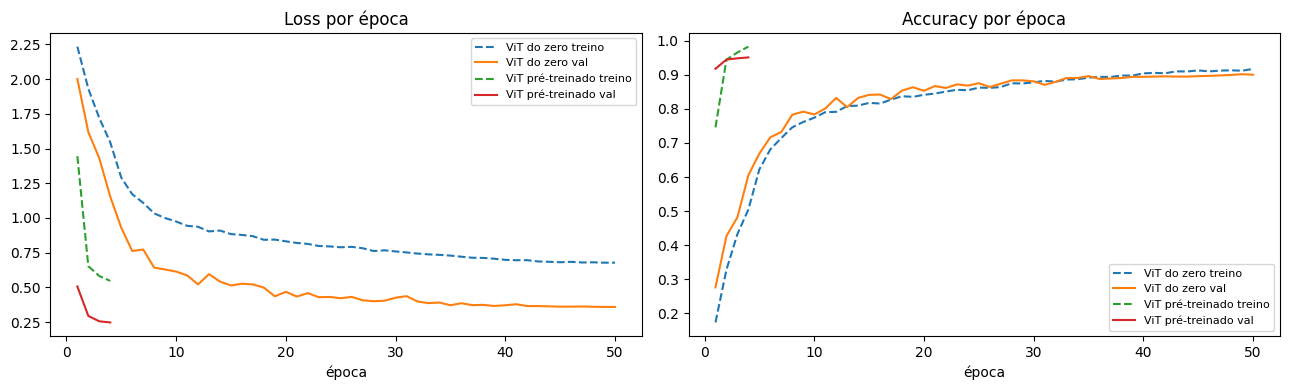

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for h, name in [(hist_s, "ViT do zero"), (hist_p, "ViT pré-treinado")]:
    ax[0].plot(h.epoch, h.train_loss, "--", label=f"{name} treino"); ax[0].plot(h.epoch, h.val_loss, "-", label=f"{name} val")
    ax[1].plot(h.epoch, h.train_acc, "--", label=f"{name} treino"); ax[1].plot(h.epoch, h.val_acc, "-", label=f"{name} val")
ax[0].set_title("Loss por época"); ax[1].set_title("Accuracy por época")
for a in ax: a.set_xlabel("época"); a.legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT_DIR / "a1_curvas.png", dpi=150); plt.show()

In [16]:
@torch.no_grad()
def throughput(model, loader, n_batches=10):
    model.eval()
    xs = [x for _, (x, _) in zip(range(n_batches), loader)]
    with torch.autocast(DEVICE.type, enabled=AMP): model(xs[0].to(DEVICE))   # aquecimento
    if AMP: torch.cuda.synchronize()
    t0, n = time.time(), 0
    for x in xs:
        with torch.autocast(DEVICE.type, enabled=AMP): model(x.to(DEVICE))
        n += len(x)
    if AMP: torch.cuda.synchronize()
    return n / (time.time() - t0)

results = {}
for name, m, te_loader, h, t, bv, res in [
        ("ViT do zero", vit_scratch, te_s, hist_s, time_s, bestval_s, "64×64, patch 8"),
        ("ViT-Base pré-treinado (fine-tuning)", vit_pt, te_p, hist_p, time_p, bestval_p, "224×224, patch 16")]:
    loss, acc, ys, ps = evaluate(m, te_loader)
    results[name] = dict(ys=ys, ps=ps, row={
        "Resolução": res, "Parâmetros (M)": round(count_params(m) / 1e6, 2), "Épocas": len(h),
        "Tempo de treino (min)": round(t / 60, 1), "Melhor val acc": round(bv, 4),
        "Test accuracy": round(acc, 4), "Test macro-F1": round(f1_score(ys, ps, average="macro"), 4),
        "Inferência (img/s)": round(throughput(m, te_loader))})

comp = pd.DataFrame({k: v["row"] for k, v in results.items()}).T
display(comp)
comp.to_csv(OUT_DIR / "a1_tabela_comparativa.csv")

per_class = pd.DataFrame({"classe": CLASSES})
for name, r in results.items():
    cm = confusion_matrix(r["ys"], r["ps"], labels=range(NUM_CLASSES))
    per_class[f"recall — {name}"] = (cm.diagonal() / cm.sum(1)).round(3)
display(per_class)
per_class.to_csv(OUT_DIR / "a1_recall_por_classe.csv", index=False)

,Resolução,Parâmetros (M),Épocas,Tempo de treino (min),Melhor val acc,Test accuracy,Test macro-F1,Inferência (img/s)
ViT do zero,"64×64, patch 8",1.83,50,8.0,0.9014,0.8994,0.9025,4262
ViT-Base pré-treinado (fine-tuning),"224×224, patch 16",85.81,4,5.7,0.9507,0.9563,0.958,275


,classe,recall — ViT do zero,recall — ViT-Base pré-treinado (fine-tuning)
0,Tshirts,0.733,0.900
1,Shirts,0.833,0.973
2,Tops,0.920,0.960
3,Jeans,1.000,1.000
4,Casual Shoes,0.820,0.887
5,Sports Shoes,0.813,0.867
6,Heels,0.953,0.993
7,Handbags,0.980,1.000
8,Watches,0.987,1.000
9,Sunglasses,0.993,1.000


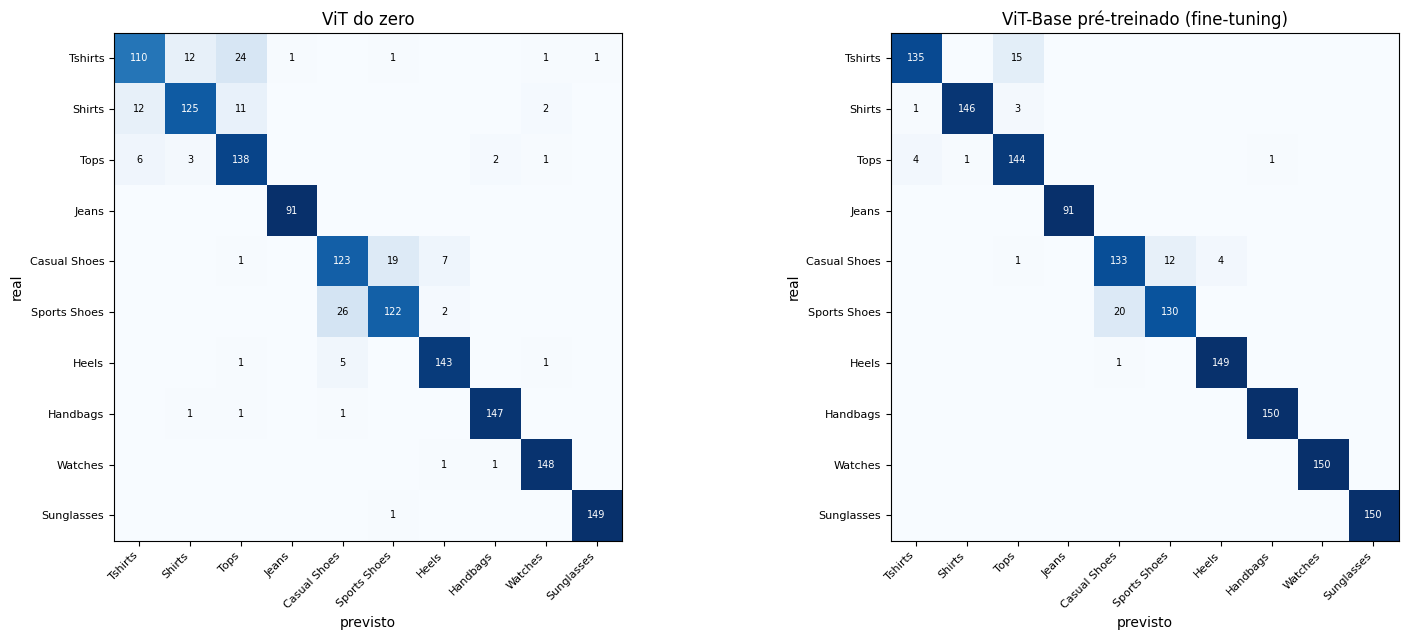

ViT do zero — confusões mais frequentes: Sports Shoes→Casual Shoes (26); Tshirts→Tops (24); Casual Shoes→Sports Shoes (19); Tshirts→Shirts (12); Shirts→Tshirts (12)
ViT-Base pré-treinado (fine-tuning) — confusões mais frequentes: Sports Shoes→Casual Shoes (20); Tshirts→Tops (15); Casual Shoes→Sports Shoes (12); Tops→Tshirts (4); Casual Shoes→Heels (4)


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
for ax, (name, r) in zip(axes, results.items()):
    cm = confusion_matrix(r["ys"], r["ps"], labels=range(NUM_CLASSES)); cmn = cm / cm.sum(1, keepdims=True)
    ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(CLASSES, rotation=45, ha="right", fontsize=8)
    ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(CLASSES, fontsize=8)
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            if cm[i, j]: ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=7, color="white" if cmn[i, j] > .5 else "black")
    ax.set_title(name); ax.set_xlabel("previsto"); ax.set_ylabel("real")
plt.tight_layout(); plt.savefig(OUT_DIR / "a1_matrizes_confusao.png", dpi=150); plt.show()

for name, r in results.items():
    cm = confusion_matrix(r["ys"], r["ps"], labels=range(NUM_CLASSES)); np.fill_diagonal(cm, 0)
    top = sorted(((cm[i, j], CLASSES[i], CLASSES[j]) for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if cm[i, j]), reverse=True)[:5]
    print(f"{name} — confusões mais frequentes: " + "; ".join(f"{a}→{b} ({n})" for n, a, b in top))

### Leitura da comparação

**O pré-treinado venceu em qualidade.** No teste, o ViT-Base com fine-tuning chegou a **95,63% de accuracy e 0,958 de macro-F1**, contra **89,94% e 0,903** do ViT treinado do zero. A diferença de 5,7 pontos não vem da arquitetura, que é da mesma família, e sim de duas coisas juntas: o pré-treinamento em 14 M imagens e a resolução maior (224 px contra 64 px). Meu experimento não separa esses dois efeitos, e assumo isso como limitação.

**O preço é custo de inferência, não de treino.** O pré-treinado tem 47× mais parâmetros (85,8 M contra 1,83 M) e é ~15× mais lento na inferência (275 contra 4.262 imagens/s na T4). No relógio de treino ele foi até mais rápido (5,7 contra 8,0 min), porque convergiu em 4 épocas enquanto o do zero precisou de 50.

**Os erros caíram exatamente nos pares difíceis que montei de propósito.** No ViT do zero, as confusões mais frequentes foram `Sports Shoes`→`Casual Shoes` (26), `Tshirts`→`Tops` (24), `Casual Shoes`→`Sports Shoes` (19) e `Tshirts`↔`Shirts` (12 em cada direção). O pré-treinado reduziu todas, mas as duas principais continuam no topo: `Sports Shoes`→`Casual Shoes` (20) e `Tshirts`→`Tops` (15).

O maior ganho foi em `Shirts` (recall de 0,833 para 0,973) e `Tshirts` (0,733 para 0,900). Separar camisa de camiseta depende de detalhe fino, como gola e linha de botões, que a 64 px com patch de 8 quase desaparece. Nos calçados o ganho foi menor (`Casual Shoes` 0,820→0,887 e `Sports Shoes` 0,813→0,867). Minha hipótese, que não verifiquei imagem a imagem, é que parte desse erro seja ambiguidade do próprio rótulo: no catálogo, tênis "lifestyle" aparecem ora como casual, ora como esportivo. `Jeans`, `Handbags`, `Watches` e `Sunglasses` ficaram entre 98% e 100% nos dois modelos, porque têm silhueta inconfundível.

**Curvas.** O ViT do zero não teve overfitting. A loss de validação ficou abaixo da de treino o tempo todo porque o treino tem dropout, augmentation e label smoothing (com smoothing, a loss de treino não chega perto de zero). A accuracy de validação ainda subia devagar na época 50 (~0,90), o que indica **underfitting**: mais épocas ou mais capacidade ainda renderiam. No pré-treinado, a loss de validação caiu de 0,506 para 0,247 em 4 épocas e já estava achatando. Com treino a 0,982 e validação a 0,951, parar em 4 épocas foi razoável.

## 8. Attention maps e interpretação

Três análises complementares:

1. **Heatmap por head (ViT do zero, última camada).** Para cada head, a linha do CLS na matriz de atenção mostra quanto o CLS pondera cada um dos 64 patches. Reorganizo em grade 8×8 e sobreponho à imagem.
2. **Attention rollout** (Abnar & Zuidema, 2020). Combina todas as camadas multiplicando as matrizes de atenção (média das heads + identidade, para contar a conexão residual). Dá uma visão agregada do que chega ao CLS.
3. **Duas métricas quantitativas no conjunto de teste.** A **distância média de atenção** por camada e head (quão longe, em pixels, cada patch olha em média, como na Fig. 7 do artigo do ViT). E a **fração da atenção do CLS que cai em fundo branco**, que neste domínio tem uma leitura direta: se o modelo gasta atenção no fundo, está desperdiçando capacidade.

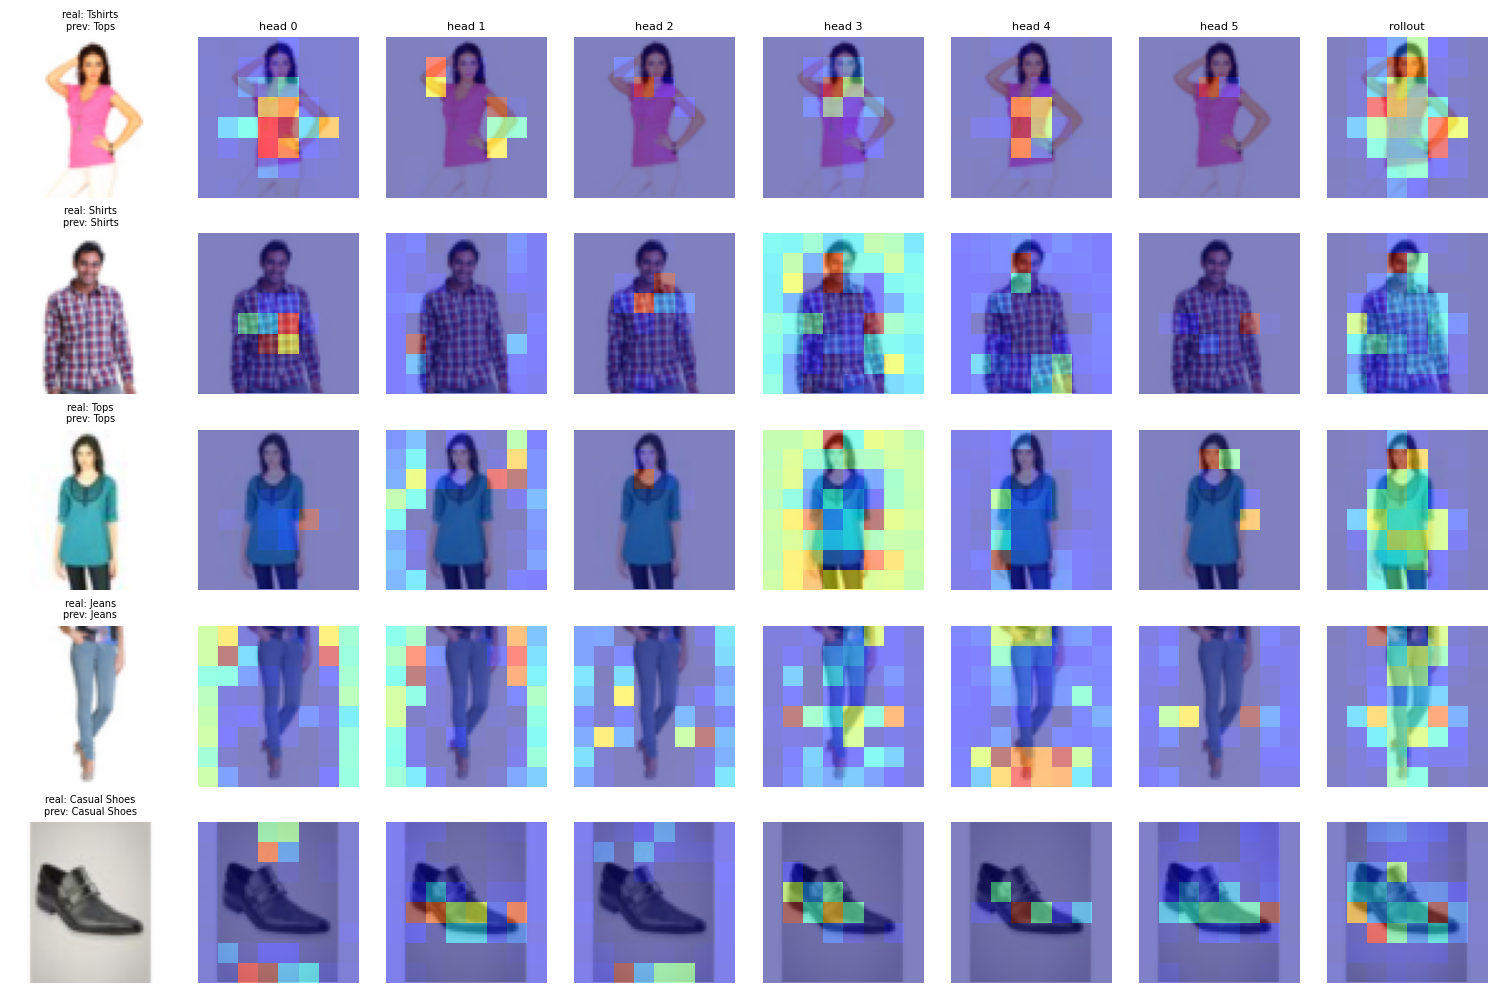

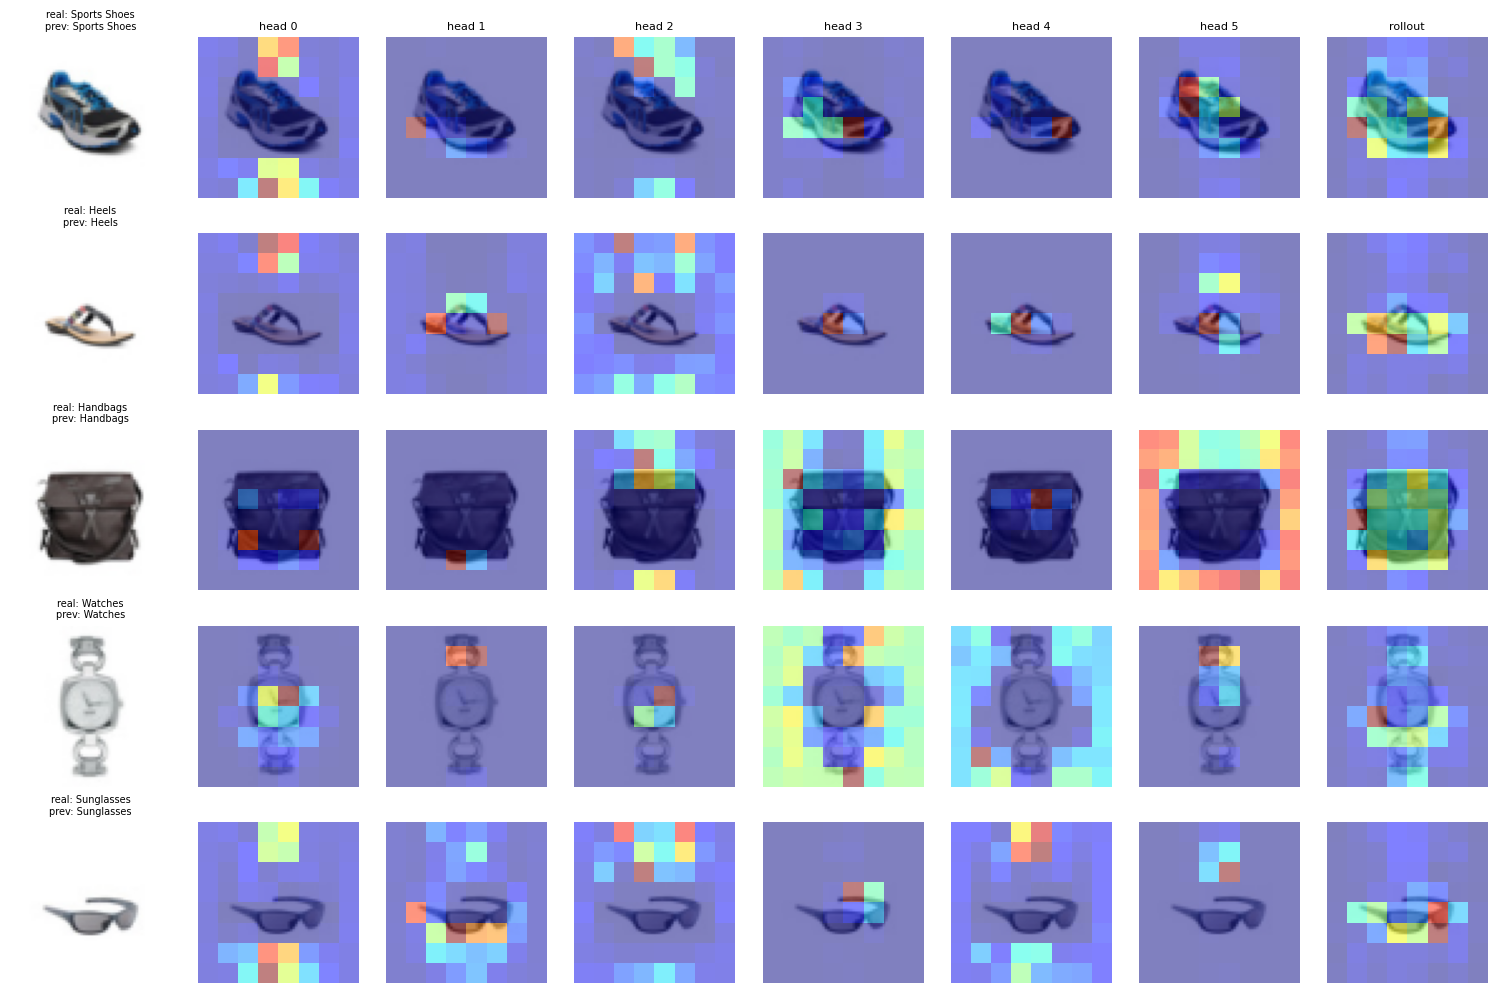

In [18]:
def denorm(t, mean, std):
    return (t.cpu() * torch.tensor(std)[:, None, None] + torch.tensor(mean)[:, None, None]).clamp(0, 1).permute(1, 2, 0).numpy()

@torch.no_grad()
def get_attn(model, x):
    model.eval()
    logits, attns = model(x.to(DEVICE), return_attn=True)
    return logits.float().cpu(), [a.float().cpu() for a in attns]     # lista de (B, H, N+1, N+1)

def rollout(attns):
    res = None
    for a in attns:
        a = a.mean(1); a = a + torch.eye(a.size(-1)); a = a / a.sum(-1, keepdim=True)
        res = a if res is None else a @ res
    return res[:, 0, 1:]                                              # CLS -> patches

def plot_heads(model, dataset_idx, tf, mean, std, fname, max_heads=6):
    xs = torch.stack([tf(IMGS[i]) for i in dataset_idx])
    logits, attns = get_attn(model, xs)
    last = attns[-1]; Hh = last.size(1); g = int(math.sqrt(last.size(-1) - 1))
    heads = list(range(min(Hh, max_heads)))
    ncol = len(heads) + 2
    fig, axes = plt.subplots(len(dataset_idx), ncol, figsize=(1.9 * ncol, 2.0 * len(dataset_idx)))
    roll = rollout(attns)
    for r, i in enumerate(dataset_idx):
        img = denorm(xs[r], mean, std)
        axes[r, 0].imshow(img); axes[r, 0].set_title(f"real: {CLASSES[YS[i]]}\nprev: {CLASSES[logits[r].argmax()]}", fontsize=7)
        for c, h in enumerate(heads):
            m = last[r, h, 0, 1:].reshape(g, g).numpy()
            axes[r, c + 1].imshow(img); axes[r, c + 1].imshow(m, cmap="jet", alpha=0.5, extent=(0, img.shape[1], img.shape[0], 0))
            if r == 0: axes[r, c + 1].set_title(f"head {h}", fontsize=8)
        rm = roll[r].reshape(g, g).numpy()
        axes[r, -1].imshow(img); axes[r, -1].imshow(rm, cmap="jet", alpha=0.5, extent=(0, img.shape[1], img.shape[0], 0))
        if r == 0: axes[r, -1].set_title("rollout", fontsize=8)
    for a in axes.ravel(): a.axis("off")
    plt.tight_layout(); plt.savefig(OUT_DIR / fname, dpi=130); plt.show()

# Um exemplo de teste por classe (5 primeiras classes e 5 últimas em duas figuras, para caber)
examples = [te_idx[np.where(YS[te_idx] == c)[0][0]] for c in range(NUM_CLASSES)]
plot_heads(vit_scratch, examples[:5], tf_eval_scratch, MEAN_SCRATCH, STD_SCRATCH, "a1_attn_scratch_1.png")
plot_heads(vit_scratch, examples[5:], tf_eval_scratch, MEAN_SCRATCH, STD_SCRATCH, "a1_attn_scratch_2.png")

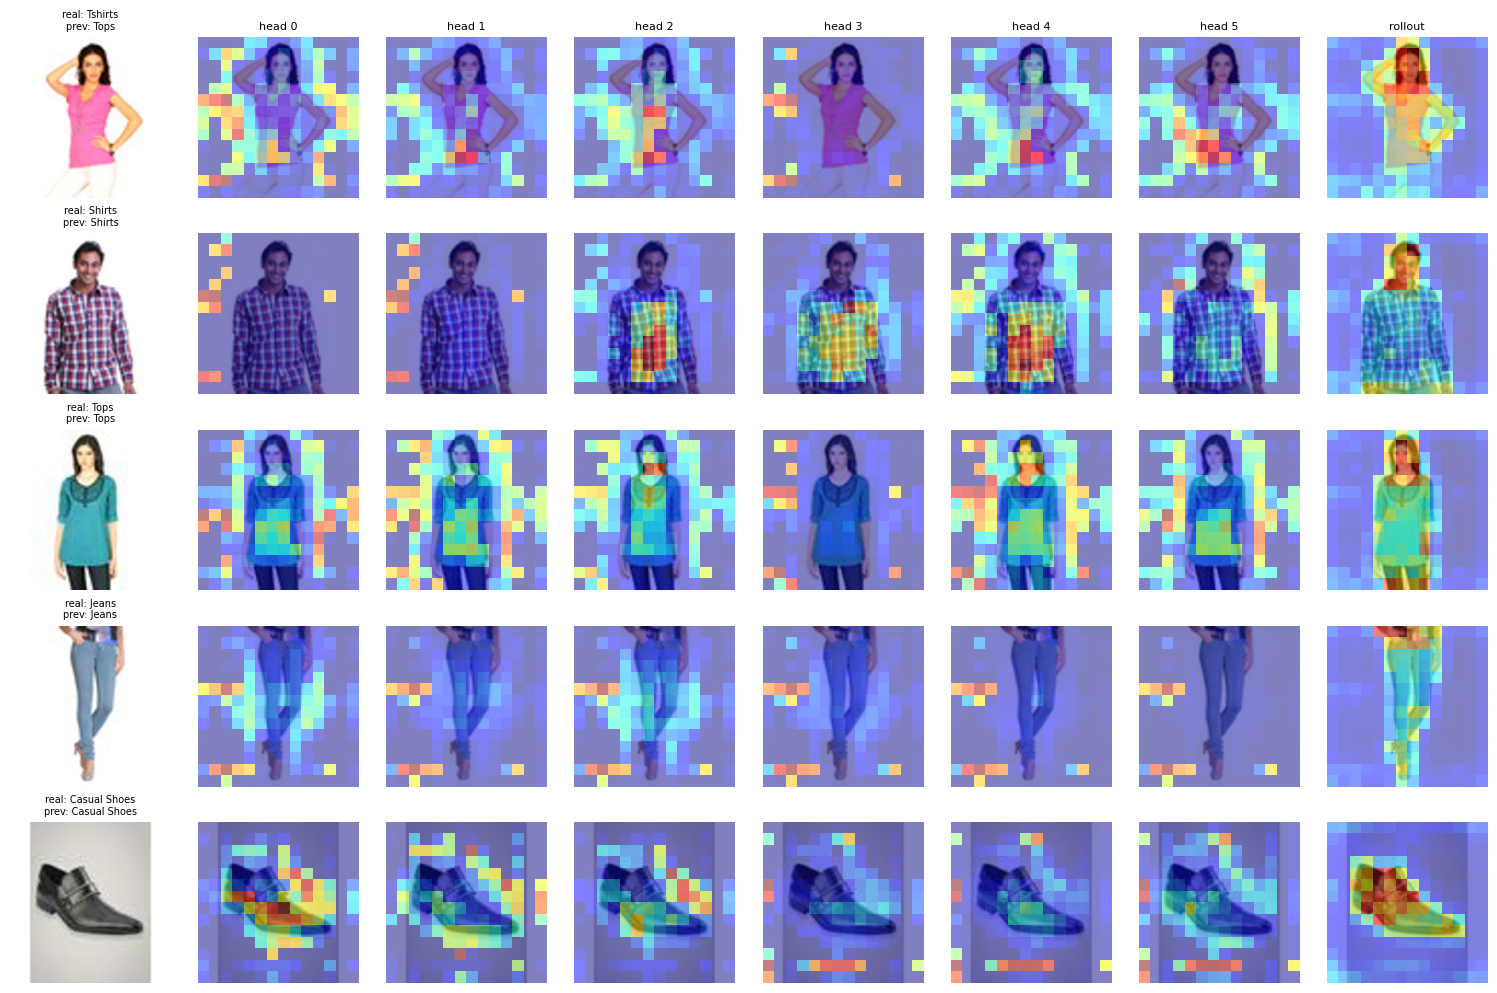

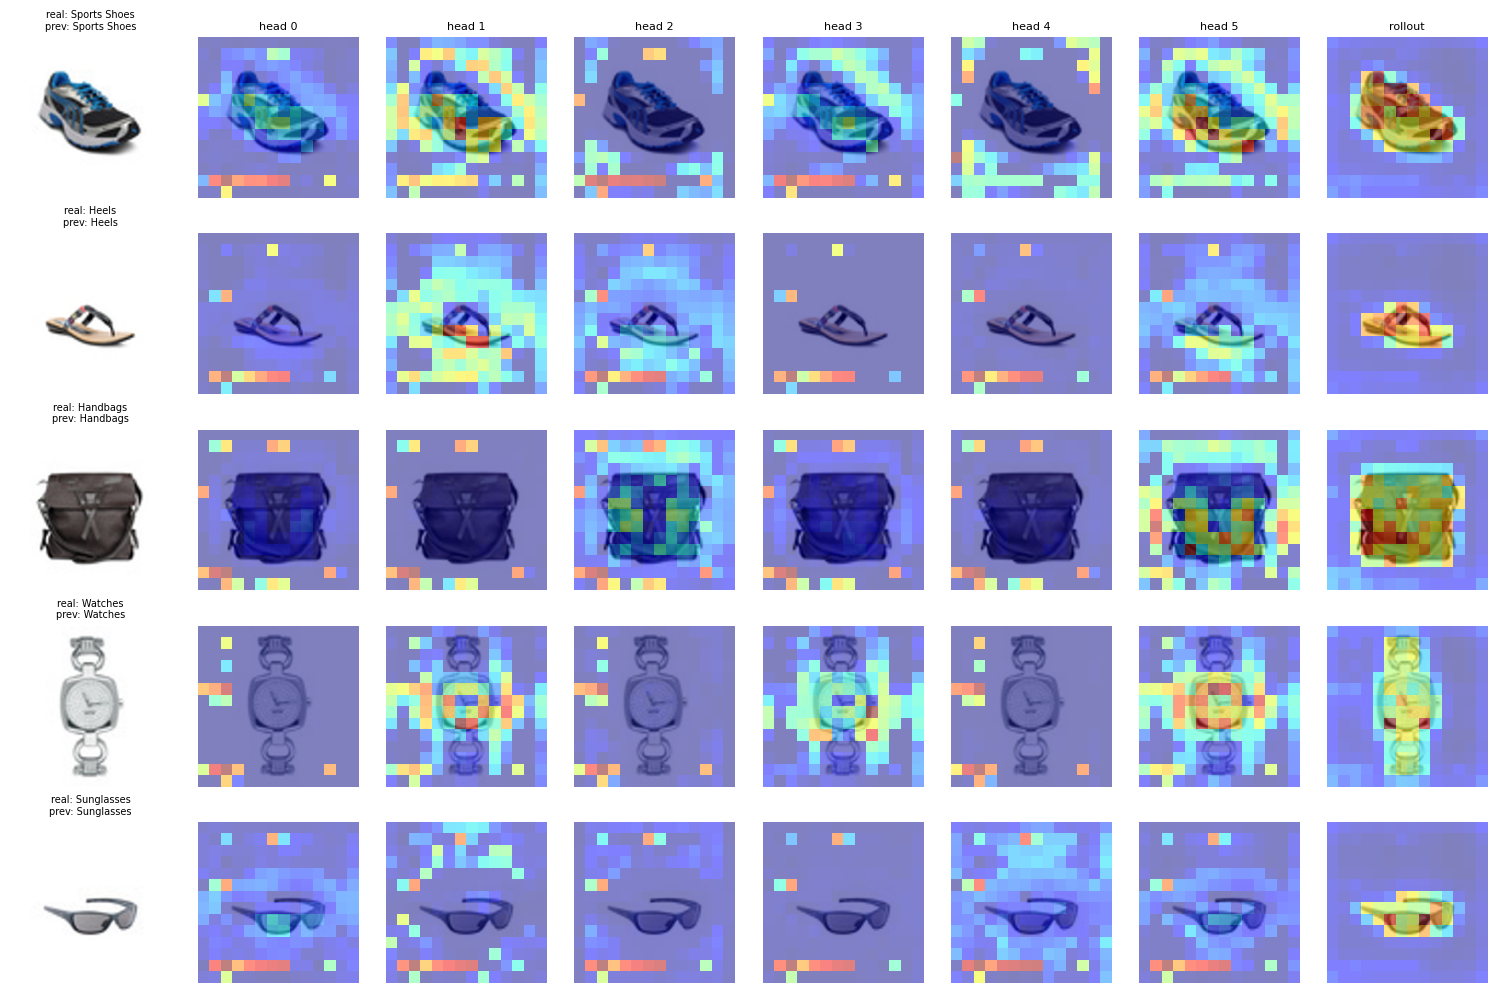

In [19]:
# O mesmo para o ViT pré-treinado (12 heads na última camada; mostro 6 + rollout)
plot_heads(vit_pt, examples[:5], tf_eval_pt, MEAN_PT, STD_PT, "a1_attn_pretrained_1.png")
plot_heads(vit_pt, examples[5:], tf_eval_pt, MEAN_PT, STD_PT, "a1_attn_pretrained_2.png")

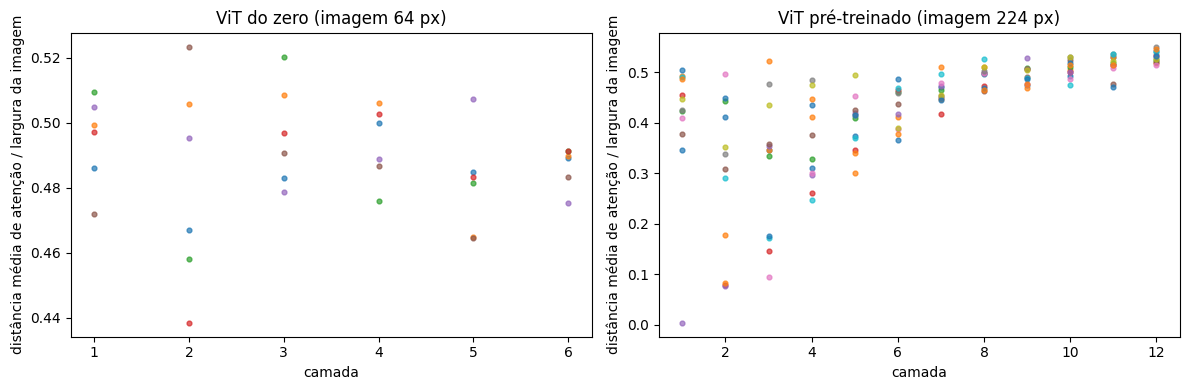

,fração de patches que são fundo,fração da atenção do CLS no fundo
ViT do zero,0.683,0.426
ViT pré-treinado,0.727,0.791


In [20]:
@torch.no_grad()
def attention_stats(model, loader, patch_px, img_px, n_batches=8):
    # Distância média de atenção (px) por camada/head e fração da atenção do CLS em patches de fundo.
    model.eval(); g = img_px // patch_px
    coords = torch.stack(torch.meshgrid(torch.arange(g), torch.arange(g), indexing="ij"), -1).reshape(-1, 2).float() * patch_px
    dist = torch.cdist(coords, coords)                                # (N, N) em pixels
    dist_sum, cnt, bg_attn, bg_frac = None, 0, [], []
    for b, (x, _) in enumerate(loader):
        if b >= n_batches: break
        _, attns = get_attn(model, x)
        A = torch.stack([a[:, :, 1:, 1:] for a in attns], 1)          # (B, L, H, N, N) só patch->patch
        A = A / A.sum(-1, keepdim=True)
        d = (A * dist).sum(-1).mean(-1)                               # (B, L, H)
        dist_sum = d.sum(0) if dist_sum is None else dist_sum + d.sum(0); cnt += len(x)
        # fundo: patch cujo pixel médio (desnormalizado) é quase branco
        raw = x * 0.5 + 0.5 if patch_px == 8 else x * torch.tensor(STD_PT)[:, None, None] + torch.tensor(MEAN_PT)[:, None, None]
        pm = F.avg_pool2d(raw.min(1, keepdim=True)[0], patch_px).flatten(1)   # (B, N)
        is_bg = pm > 0.92
        cls = attns[-1][:, :, 0, 1:].mean(1)                          # (B, N), média das heads
        cls = cls / cls.sum(-1, keepdim=True)
        bg_attn.append((cls * is_bg).sum(-1)); bg_frac.append(is_bg.float().mean(-1))
    return (dist_sum / cnt).numpy(), torch.cat(bg_attn).mean().item(), torch.cat(bg_frac).mean().item()

dist_s, bgA_s, bgF_s = attention_stats(vit_scratch, te_s, 8, 64)
dist_p, bgA_p, bgF_p = attention_stats(vit_pt, te_p, 16, 224)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, d, name, img_px in [(ax[0], dist_s, "ViT do zero (imagem 64 px)", 64), (ax[1], dist_p, "ViT pré-treinado (imagem 224 px)", 224)]:
    L, Hh = d.shape
    for h in range(Hh): a.scatter(np.arange(1, L + 1), d[:, h] / img_px, s=12, alpha=.7)
    a.set_xlabel("camada"); a.set_ylabel("distância média de atenção / largura da imagem"); a.set_title(name)
plt.tight_layout(); plt.savefig(OUT_DIR / "a1_distancia_atencao.png", dpi=150); plt.show()

bg = pd.DataFrame({"fração de patches que são fundo": [bgF_s, bgF_p],
                   "fração da atenção do CLS no fundo": [bgA_s, bgA_p]},
                  index=["ViT do zero", "ViT pré-treinado"]).round(3)
display(bg); bg.to_csv(OUT_DIR / "a1_atencao_fundo.csv")

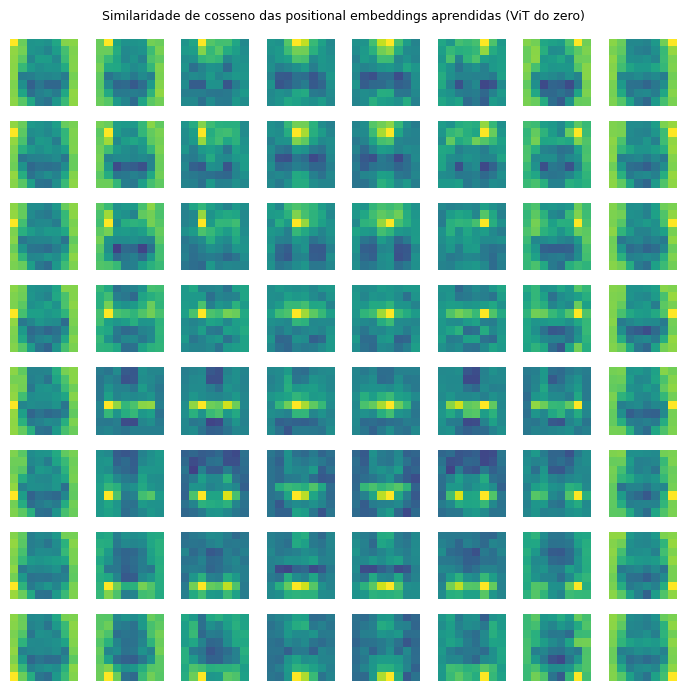

In [21]:
# Similaridade entre as positional embeddings aprendidas pelo ViT do zero:
# cada quadradinho mostra a similaridade de cosseno de uma posição com todas as outras.
pe = vit_scratch.pos_embed[0, 1:].detach().float().cpu()
pe = F.normalize(pe, dim=-1); sim = (pe @ pe.T).reshape(8, 8, 8, 8).numpy()
fig, axes = plt.subplots(8, 8, figsize=(7, 7))
for i in range(8):
    for j in range(8):
        axes[i, j].imshow(sim[i, j], cmap="viridis", vmin=-1, vmax=1); axes[i, j].axis("off")
plt.suptitle("Similaridade de cosseno das positional embeddings aprendidas (ViT do zero)", fontsize=9)
plt.tight_layout(); plt.savefig(OUT_DIR / "a1_pos_embedding_sim.png", dpi=130); plt.show()

In [22]:
summary = {"classes": CLASSES, "n_treino": len(tr_idx), "n_val": len(va_idx), "n_teste": len(te_idx),
           "tabela": comp.astype(str).to_dict(), "atencao_fundo": bg.to_dict()}
(OUT_DIR / "a1_resumo.json").write_text(json.dumps(summary, indent=2, ensure_ascii=False))
print(json.dumps(summary["tabela"], indent=2, ensure_ascii=False))

{
  "Resolução": {
    "ViT do zero": "64×64, patch 8",
    "ViT-Base pré-treinado (fine-tuning)": "224×224, patch 16"
  },
  "Parâmetros (M)": {
    "ViT do zero": "1.83",
    "ViT-Base pré-treinado (fine-tuning)": "85.81"
  },
  "Épocas": {
    "ViT do zero": "50",
    "ViT-Base pré-treinado (fine-tuning)": "4"
  },
  "Tempo de treino (min)": {
    "ViT do zero": "8.0",
    "ViT-Base pré-treinado (fine-tuning)": "5.7"
  },
  "Melhor val acc": {
    "ViT do zero": "0.9014",
    "ViT-Base pré-treinado (fine-tuning)": "0.9507"
  },
  "Test accuracy": {
    "ViT do zero": "0.8994",
    "ViT-Base pré-treinado (fine-tuning)": "0.9563"
  },
  "Test macro-F1": {
    "ViT do zero": "0.9025",
    "ViT-Base pré-treinado (fine-tuning)": "0.958"
  },
  "Inferência (img/s)": {
    "ViT do zero": "4262",
    "ViT-Base pré-treinado (fine-tuning)": "275"
  }
}


### Interpretação dos attention maps

**ViT do zero: a atenção do CLS vai para o produto.** Na tabela de fundo, 68,3% dos patches são fundo branco, mas só 42,6% da atenção do CLS cai neles. Ou seja, os ~32% de patches com produto recebem ~57% da atenção. O modelo aprendeu sozinho a ignorar o branco, sem nenhuma máscara.

Nas figuras por head, algumas heads se especializaram em regiões que fazem sentido para a classe. Na camisa xadrez, a head 2 vai para a gola e o peito, que é o que separa `Shirts` de `Tshirts`. Nos sapatos, as heads 1, 3 e 4 vão para o solado e a lateral. Outras heads ficam espalhadas pelo fundo, como várias delas no exemplo de `Jeans`, e parecem funcionar mais como "média geral" do que como detector de parte.

**Distância de atenção: o ViT do zero não aprendeu heads locais.** Em todas as 6 camadas, as heads olham em média a ~45–52% da largura da imagem, sem separação entre local e global. O pré-treinado reproduz o padrão da Fig. 7 do artigo do ViT: nas camadas 1 a 4 há heads bem locais (0,0 a 0,2 da largura) convivendo com heads globais, e da camada 8 em diante todas são globais (~0,5). Esse é o custo de não ter viés indutivo de localidade: com 6,7 mil imagens, o modelo do zero não teve dado suficiente para descobrir que patches vizinhos importam mais, algo que uma CNN já traz de fábrica.

**O paradoxo do pré-treinado: 79,1% da atenção do CLS vai para o fundo**, mais do que a fração de patches de fundo (72,7%). Olhando os heatmaps da última camada, a atenção não se espalha pelo fundo. Ela se concentra em **poucos patches isolados de fundo branco**, nas bordas e cantos (por exemplo, na faixa inferior do sapato e na borda esquerda de várias roupas).

Esse comportamento é consistente com o que Darcet et al. (2024, *Vision Transformers Need Registers*) descreveram: ViTs grandes, treinados por muito tempo, passam a reaproveitar patches de pouca informação como "rascunho" para guardar informação global, e o CLS lê dali. Não provei isso neste notebook, mas o padrão bate e a consequência prática importa: **a atenção da última camada não é uma boa explicação do que o ViT-Base está olhando**. O attention rollout, que combina todas as camadas e considera a conexão residual, fica concentrado no produto (tronco e gola nas roupas, corpo do sapato), e é a visualização mais confiável para esse modelo. O ViT do zero, pequeno e treinado por pouco tempo, não mostra esse artefato, o que também é coerente com o artigo.

**Positional embeddings do ViT do zero.** O mosaico de similaridade mostra que o modelo aprendeu estrutura 2D sem nenhuma informação 2D no código (a PE é só uma lista de 65 vetores). Cada posição é mais parecida com as da mesma linha, o que aparece como faixas horizontais claras. Há dois detalhes que eu não tinha previsto:

- A similaridade é **espelhada**: a posição (linha 4, coluna 1) é parecida com a (linha 4, coluna 6). Isso é efeito direto do `RandomHorizontalFlip`: como o conteúdo da coluna *j* aparece com a mesma frequência na coluna 7−*j*, o modelo não tem motivo para diferenciá-las.
- As colunas das bordas (0 e 7) são parecidas entre si e com quase tudo nas bordas, porque são quase sempre fundo branco.

## 9. Análises escritas

### 9.1 Pré-treinamento do BERT vs. do ViT: o que cada um maximiza

O **BERT** é pré-treinado de forma **auto-supervisionada** em texto sem rótulo. A tarefa principal é *masked language modeling*: 15% dos tokens são escondidos e o modelo maximiza a verossimilhança de recuperar o token original a partir do contexto dos dois lados. Havia também o *next sentence prediction*, que trabalhos posteriores (RoBERTa) mostraram ser dispensável. O que o BERT maximiza, portanto, é a capacidade de **representar cada token em função do contexto**. Não precisa de rótulo nenhum, então escala para bilhões de palavras.

O **ViT original** é pré-treinado de forma **supervisionada**: classificação no ImageNet-21k ou no JFT-300M, maximizando a verossimilhança do rótulo da imagem, lido pelo CLS. Ele maximiza uma representação **global e discriminativa entre classes**, a mesma lógica das CNNs pré-treinadas no ImageNet. O custo é depender de rótulos em escala: o próprio artigo mostra que o ViT só supera ResNets quando pré-treinado em 14 M a 300 M imagens.

Por que o ViT não copiou o BERT desde o início? Porque um token de texto é um símbolo discreto de um vocabulário fechado, e prever qual palavra falta é uma tarefa difícil e informativa. Um patch é contínuo e muito redundante com os vizinhos, então reconstruir um patch escondido a partir dos vizinhos é fácil demais e ensina pouco. Os métodos que trouxeram a ideia do BERT para visão (BEiT, MAE) precisaram adaptar: o BEiT prevê tokens visuais discretos, e o MAE mascara **75%** dos patches, contra 15% no BERT, para que a tarefa exija entender o objeto e não só interpolar.

O checkpoint que usei (`vit-base-patch16-224-in21k`) segue o esquema supervisionado original. Isso ajuda no meu problema, que também é de classificação por categoria de objeto.

### 9.2 DeiT e Swin Transformer: o que resolvem que o ViT original não resolve

**DeiT (Data-efficient Image Transformer, Touvron et al., 2021)** resolve a **dependência de dados**. O ViT precisava de JFT-300M, um dataset privado do Google. O DeiT treina o mesmo tipo de arquitetura só no ImageNet-1k (1,3 M imagens), com duas mudanças: uma receita pesada de augmentation e regularização (RandAugment, Mixup, CutMix, random erasing, stochastic depth, repeated augmentation) e um **token de destilação**, um segundo token além do CLS que aprende a imitar as previsões de uma CNN professora (RegNet). A CNN "empresta" o viés indutivo de localidade que falta ao transformer. É a referência mais próxima do meu cenário: meu ViT do zero sofre exatamente com pouco dado.

**Swin Transformer (Liu et al., 2021)** resolve **custo computacional e ausência de hierarquia**. No ViT, a atenção é global entre todos os patches, com custo quadrático no número de tokens. Isso inviabiliza alta resolução, e a saída tem uma única escala, ruim para detecção e segmentação. O Swin calcula atenção só dentro de **janelas locais** (custo linear no tamanho da imagem) e alterna camadas com **janelas deslocadas** (*shifted windows*) para que a informação atravesse as bordas das janelas. Entre estágios, faz *patch merging*, reduzindo a resolução e aumentando os canais como uma CNN, o que gera mapas de features multiescala. Com isso, virou backbone para tarefas densas, onde o ViT puro não funcionava bem.

### 9.3 Quando Vision Transformers superam CNNs, e quando CNNs são preferíveis

A diferença central é o **viés indutivo**. Uma CNN já nasce assumindo localidade (um pixel se relaciona com os vizinhos) e equivariância a translação (o mesmo filtro em toda a imagem). O ViT assume quase nada: só o corte em patches e a posição aprendida. Ele precisa aprender, a partir dos dados, que patches vizinhos importam mais.

- **ViT tende a ganhar** com muitos dados ou com um bom modelo pré-treinado disponível; quando relações de longo alcance importam (atenção global desde a primeira camada); em alta capacidade, em que escala melhor com dados e compute; e em cenários multimodais, como no CLIP, onde a mesma arquitetura de tokens serve para imagem e texto.
- **CNN tende a ganhar** quando os dados são poucos e não há pré-treinamento no domínio; quando o hardware é limitado (borda, mobile, latência baixa); quando as pistas são locais e texturais; e em imagens pequenas, onde a atenção global tem pouco a oferecer.

**No meu domínio:** produtos centralizados, fundo branco, imagens de ~64 px, ~7 mil imagens de treino. O viés de localidade de uma CNN combina bem com isso e o ViT do zero tem desvantagem estrutural, o que os resultados confirmam: 89,9% de accuracy do ViT do zero, com as heads todas globais e sem nenhuma head local mesmo nas primeiras camadas. Com pré-treinamento, a desvantagem some, porque o ViT-Base chega com as invariâncias já aprendidas em 14 M imagens. Para produção em um marketplace, eu avaliaria também uma CNN pré-treinada pequena (EfficientNet-B0/ConvNeXt-Tiny), que provavelmente chegaria perto do ViT-Base com uma fração do custo de inferência.

### 9.4 Escolha de arquitetura para o domínio, com base nos dados

A arquitetura que eu levaria para o problema é o **ViT-Base pré-treinado com fine-tuning**: 95,63% de accuracy e 0,958 de macro-F1 no teste, contra 89,94% e 0,903 do ViT do zero. O ganho está onde importa para o negócio. Um catálogo que confunde camisa com camiseta põe o produto no filtro errado e no feed de anúncio errado, e foi justamente em `Shirts` e `Tshirts` que o pré-treinado mais melhorou (recall de 0,83→0,97 e 0,73→0,90).

O custo é 47× mais parâmetros e inferência ~15× mais lenta. Mesmo assim, 275 imagens/s numa T4 classificam um catálogo de 100 mil produtos em ~6 minutos e dão conta de sugerir a categoria em tempo real no cadastro. O custo pesa mais em infraestrutura (GPU) do que em latência.

O ViT do zero só faria sentido se a inferência precisasse rodar em CPU ou no celular do vendedor. Nesse caso, eu testaria antes uma CNN pequena pré-treinada, que tende a ficar mais perto do ViT-Base com uma fração do custo.

### 9.5 O que eu mudaria

- **No ViT do zero:** seguir a receita do DeiT (Mixup/CutMix, RandAugment leve sem mexer em matiz, stochastic depth) e treinar por mais épocas, que é o jeito mais direto de compensar a falta de viés indutivo. Também testaria patch 4 com menos camadas.
- **No pré-treinado:** testar fine-tuning em duas fases (primeiro só o head, depois o modelo inteiro), learning rate menor nas camadas iniciais (*layer-wise lr decay*) e um DeiT-Small ou Swin-Tiny, mais baratos que o ViT-Base.
- **No experimento:** treinar o ViT-Base também a 64 px (interpolando a PE) para separar o efeito da resolução do efeito do pré-treinamento, e montar uma grade de erros dos calçados para testar a hipótese de rótulo ambíguo entre casual e esportivo.
- **No problema:** usar o dataset inteiro (sem o teto de 1.000) com loss ponderada, e incluir o texto do título do produto num modelo multimodal (CLIP), que é como marketplaces reais fazem.